# Track-before-detect (IE-PHPMHT) vs detect-then-track (GLMB / LMB / GNN) on simulated drones

Same environment as `drone_tracking_playground.ipynb` (`dronebench.simulate`): planar drones that hover, cruise,
accelerate and circle, 1–5 px Gaussian blobs, heavy clutter of persistent and one-frame blobs, white noise σ = 1.
Default here: **SNR 2, clutter 1–5 px** (the same size as the drones), 320×240.

| | pipeline |
|---|---|
| **GLMB-gibbs, LMB-gibbs, GNN** | per-frame point detector (background subtraction → high-pass → matched filter → threshold + NMS + LoG size gate) → tracker on the detections |
| **IE-PHPMHT** | Herrmann, García-Fernández & Brekke, *Histogram-PMHT with integrated target existence*, [arXiv:2504.20526](https://arxiv.org/abs/2504.20526), as implemented in `Neural-Glimpse/track_before_detect_exp` (`notebooks/iephpmht_1080p_realtime.ipynb`), refactored into the `iephpmht` package. **No detection threshold**: the raw frame becomes Poisson-like cell counts, Bernoulli components with an IMM (CV, CT±, CA) are fitted to them by EM, and existence comes from the fitted Poisson rate (eq. 47). |

**Protocol**
1. Every sequence has a **60-frame pre-roll**. All algorithms see it, and background models and tracks start there. Metrics are computed on the following **80 frames** only.
2. **Calibration** minimises mean GOSPA (c = 10 px, p = 2, α = 2) on **training seeds 11–13**. It uses a random search, then a shrinking local search around the best point, always starting from the defaults.
   - The detector threshold is tuned jointly with each tracker.
   - IE-PHPMHT's priors (α, β, γ, p_s, p_b) come from the paper/project **empirical-Bayes calibration** on a separate labelled **calibration seed 100**, recomputed for every front-end setting. Its structural, motion and reporting parameters are searched on top.
3. **Comparison** on **held-out test seeds 1–6**: the default and the calibrated configuration of every algorithm.
4. **Latency**: single thread, CPU, frames in memory.
   - Detection pipelines: detector + tracker.
   - IE-PHPMHT: front end + filter (the project's NumPy port of its CUDA front end).

IE-PHPMHT got a second stage on top: a 30-trial local refinement with widened bounds, then a line search over `p_b_scale`, still on training seeds only, because its first search ended at a bound.

Calibration results are cached in `calib/*.json`; `run_calibration.py <algo>` regenerates them (≈ 15–40 min per algorithm).

In [1]:
import os, sys, json, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from dataclasses import replace, asdict
warnings.filterwarnings("ignore", category=RuntimeWarning)
sys.path.insert(0, os.path.abspath("."))

from dronebench import ScenarioConfig, DetectorConfig, TrackerConfig, simulate
from dronebench.calibrate import (Bench, compare, summary_table, from_jsonable, load_results, to_experiment,
                                  TBDCalibrator, effective_priors)
from dronebench.tbd import TBDConfig, SeqSource, eb_calibrate, IEPHPMHT_ROOT
from dronebench import viz
import run_calibration as RC
import iephpmht as ip

pd.set_option("display.precision", 3); pd.set_option("display.width", 200)
print("iephpmht from", IEPHPMHT_ROOT, "| front end backend:", "CUDA" if ip.cuda_available() else "CPU (NumPy)")

iephpmht from C:\Users\webrt\Documents\gitcloned\track_before_detect_exp | front end backend: CPU (NumPy)


## 1. Scenario: edit here

`SETUP` is shared with `run_calibration.py`. If you change the scenario (SNR, clutter, size), the cached calibration
no longer matches it. Set `RECALIBRATE = True` to rerun the searches inside the notebook (slow), or run them in parallel
from a shell: `python run_calibration.py IE-PHPMHT` etc.

In [2]:
SETUP = dict(RC.SETUP)           # snr=2.0, clutter_size_px=(1,5), pre=60, n_eval=80, train 11-13, calib 100, test 1-6
# SETUP.update(snr=3.0)          # <- play here
RECALIBRATE = False
CALIB_DIR = "calib"
ALGOS = ["GLMB-gibbs", "LMB-gibbs", "GNN", "IE-PHPMHT"]

scn = RC.scenario(SETUP)
PRE = SETUP["pre"]
print(scn)

ScenarioConfig(width=320, height=240, n_frames=140, noise_sigma=1.0, bg_level=0.0, bg_gradient=2.0, n_targets_init=(3, 5), birth_rate=0.03, p_death=0.004, max_targets=10, spawn='edge', stay_in_view=True, target_size_px=(1.0, 5.0), snr=2.0, snr_fluctuation=0.15, mode_probs={'hover': 0.3, 'cruise': 0.25, 'accel': 0.25, 'circle': 0.2}, dwell_frames=(10, 30), v_max=4.0, cruise_speed=(0.8, 3.0), accel=(0.08, 0.35), circle_radius=(8.0, 30.0), hover_jitter=0.15, accel_noise=0.05, n_static_clutter=60, moving_clutter_frac=0.0, clutter_speed=0.6, transient_clutter_rate=15.0, clutter_size_px=(1.0, 5.0), clutter_snr=(0.5, 5.0))


## 2. What each pipeline sees

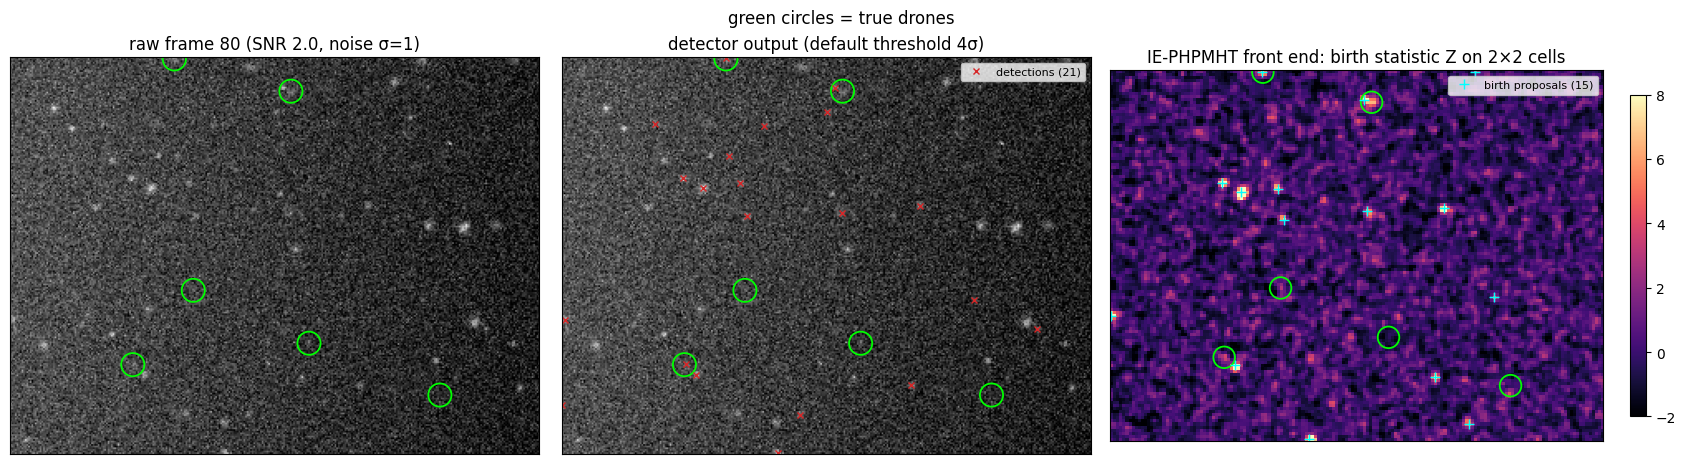

In [3]:
seq = simulate(scn, SETUP["test_seeds"][0])
k = PRE + 20
det_default = DetectorConfig()
from dronebench.detector import detect_sequence
Z, _, _ = detect_sequence(seq.frames[:k + 1], det_default)
fe = ip.make_frontend(seq.frames.shape[1:], 2, 0.7, backend="cpu", n_warm=40)
src = SeqSource(seq)
for j in range(k + 1):
    fe.process(src.frame(j))
cand, zval = fe.birth_candidates()

t = seq.truth[k]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6))
ax[0].imshow(seq.frames[k], cmap="gray", vmin=-3, vmax=6); ax[0].set_title(f"raw frame {k} (SNR {scn.snr}, noise σ=1)")
ax[1].imshow(seq.frames[k], cmap="gray", vmin=-3, vmax=6)
ax[1].plot(Z[k][0], Z[k][1], "x", c="tab:red", ms=5, label=f"detections ({Z[k].shape[1]})")
ax[1].set_title("detector output (default threshold 4σ)")
im = ax[2].imshow(fe.T, cmap="magma", vmin=-2, vmax=8, extent=(-0.5, seq.cfg.width - 0.5, seq.cfg.height - 0.5, -0.5))
ax[2].plot(cand[:, 0] * 2 - 0.5, cand[:, 1] * 2 - 0.5, "+", c="cyan", ms=7, label=f"birth proposals ({len(cand)})")
ax[2].set_title("IE-PHPMHT front end: birth statistic Z on 2×2 cells"); plt.colorbar(im, ax=ax[2], fraction=0.03)
for a in ax:
    for x, y in t["pos"]:
        a.add_patch(plt.Circle((x, y), 7, fill=False, ec="lime", lw=1.3))
    a.set_xticks([]); a.set_yticks([]); a.set_xlim(-0.5, seq.cfg.width - 0.5); a.set_ylim(seq.cfg.height - 0.5, -0.5)
ax[1].legend(loc="upper right", fontsize=8); ax[2].legend(loc="upper right", fontsize=8)
fig.suptitle("green circles = true drones", y=1.0); plt.tight_layout(); plt.show()

## 3. Calibration

Loads `calib/<algo>.json` (written by `run_calibration.py`), or runs the search here if a file is missing or `RECALIBRATE` is set.

,trials,minutes,train_GOSPA_default,train_GOSPA_calibrated
algorithm,,,,
GLMB-gibbs,27,23.078,9.963,6.837
LMB-gibbs,41,29.042,9.907,6.828
GNN,51,9.075,13.849,10.863
IE-PHPMHT,100,28.153,37.653,10.309


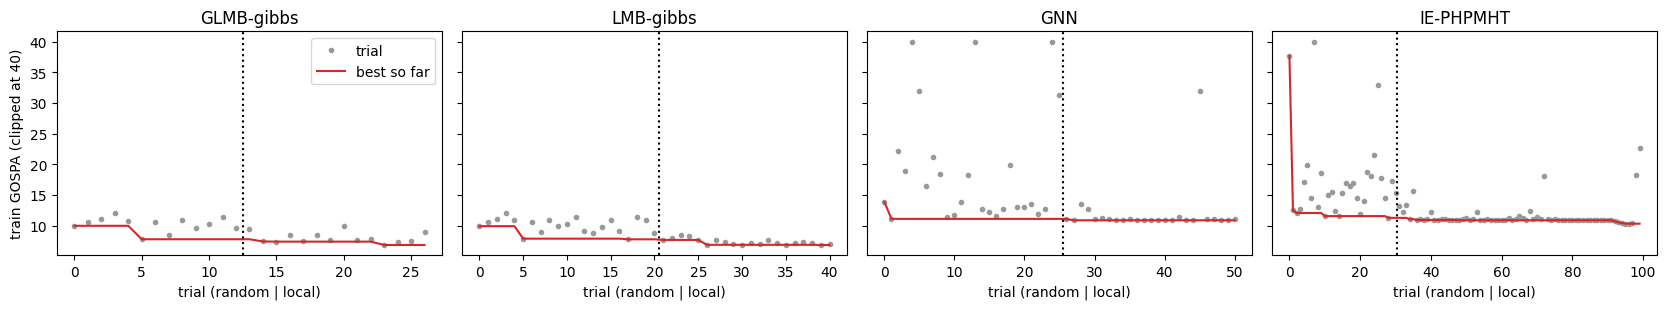

In [4]:
CAL = {}
for algo in ALGOS:
    path = os.path.join(CALIB_DIR, f"{algo}.json")
    if RECALIBRATE or not os.path.exists(path):
        print(f"calibrating {algo} ...")
        res = RC.calibrate_one(algo, setup=SETUP)
        os.makedirs(CALIB_DIR, exist_ok=True)
        from dronebench.calibrate import save_results
        save_results(path, res, meta=dict(setup=SETUP))
    d = load_results(path)
    if d["meta"]["setup"] != json.loads(json.dumps(SETUP)):
        print(f"WARNING {algo}: calibration was made for a different SETUP: {d['meta']['setup']}")
    CAL[algo] = d["results"]

rows = []
for algo, r in CAL.items():
    rows.append(dict(algorithm=algo, trials=r["n_trials"], minutes=r["seconds"] / 60,
                     train_GOSPA_default=r["default_train_gospa"], train_GOSPA_calibrated=r["train_gospa"]))
display(pd.DataFrame(rows).set_index("algorithm"))

fig, axs = plt.subplots(1, len(CAL), figsize=(4.2 * len(CAL), 3.2), sharey=True)
for ax, (algo, r) in zip(axs, CAL.items()):
    h = pd.DataFrame(r["history"])
    ax.plot(h.score.clip(upper=40), ".", c="0.6", label="trial")
    ax.plot(h.score.cummin(), "-", c="tab:red", label="best so far")
    ax.axvline((h.phase == "random").sum() + 0.5, ls=":", c="k")
    ax.set_title(algo); ax.set_xlabel("trial (random | local)")
axs[0].set_ylabel("train GOSPA (clipped at 40)"); axs[0].legend(); plt.tight_layout(); plt.show()

In [5]:
# default vs calibrated parameters
DEF = RC.default_configs()
TUNED, TBD_CAL = {}, None
for algo in ALGOS:
    det, trk, tbd, cal, _ = from_jsonable(CAL[algo])
    TUNED[algo] = (det, trk) if algo != "IE-PHPMHT" else (tbd, cal)
    if algo == "IE-PHPMHT":
        TBD_CAL = cal

def diff_params(a, b, prefix):
    da, db = asdict(a), asdict(b)
    return {f"{prefix}.{k}": (da[k], db[k]) for k in da if da[k] != db[k]}

for algo in ALGOS:
    if algo == "IE-PHPMHT":
        d = diff_params(DEF[algo][0], TUNED[algo][0], "tbd")
    else:
        d = {**diff_params(DEF[algo][0], TUNED[algo][0], "detector"), **diff_params(DEF[algo][1], TUNED[algo][1], "tracker")}
    print(f"--- {algo}")
    for k, (a, b) in d.items():
        fa = f"{a:.4g}" if isinstance(a, float) else str(a); fb = f"{b:.4g}" if isinstance(b, float) else str(b)
        print(f"   {k:28s} {fa:>10s} -> {fb}")

--- GLMB-gibbs
   detector.threshold                    4 -> 3
   tracker.sigma_v                     0.6 -> 0.4882
   tracker.sigma_r                       1 -> 0.9607
   tracker.P_D                        0.75 -> 0.7885
   tracker.P_S                        0.98 -> 0.9902
   tracker.p_birth                    0.01 -> 0.0416
   tracker.lambda_b                    0.2 -> 0.1325
   tracker.birth_vel_std               2.5 -> 1.596
--- LMB-gibbs
   detector.threshold                    4 -> 3
   tracker.sigma_v                     0.6 -> 0.5868
   tracker.sigma_r                       1 -> 1.146
   tracker.P_D                        0.75 -> 0.5614
   tracker.P_S                        0.98 -> 0.9339
   tracker.p_birth                    0.01 -> 0.009794
   tracker.lambda_b                    0.2 -> 0.3339
   tracker.birth_vel_std               2.5 -> 2.058
--- GNN
   detector.threshold                    4 -> 4.25
   tracker.sigma_v                     0.6 -> 0.2424
   tracker.sigma_r    

### IE-PHPMHT priors: empirical Bayes, and why γ needs care

The empirical-Bayes step (project `calibrate`) fits the following on the calibration seed:
- **α, β**: Gamma, by method of moments, to single-frame Poisson-rate MLEs at the **true** drone positions;
- **γ**: 1 / mean rate MLE at random **target-free** positions, which is the rate a Bernoulli sitting on nothing gets;
- **p_s** (survival) and **p_b** (share of birth proposals that are real new drones), from the truth stream.

At SNR 2 the on-target Gamma is very broad. A confirmed Bernoulli that has lost its target keeps a posterior rate near (a − 1)/(b + 1) ≈ 3. At that rate, eq. 47's target likelihood G(λ; α, β) and clutter likelihood E(λ; γ) are about equal, so with the fixed-position γ **false tracks sustain themselves**.

A drifting Bernoulli is not at a fixed position. EM moves it to the local intensity maximum, so the right "nothing there" reference is the **position-free** MLE (best rate within ±1 cell, `off_adapt`). The adapter therefore has `gamma_mix`, which log-interpolates γ between the paper's definition (0) and the position-free one (1). Like p_s and t_conf, it is chosen by the search, not by hand.

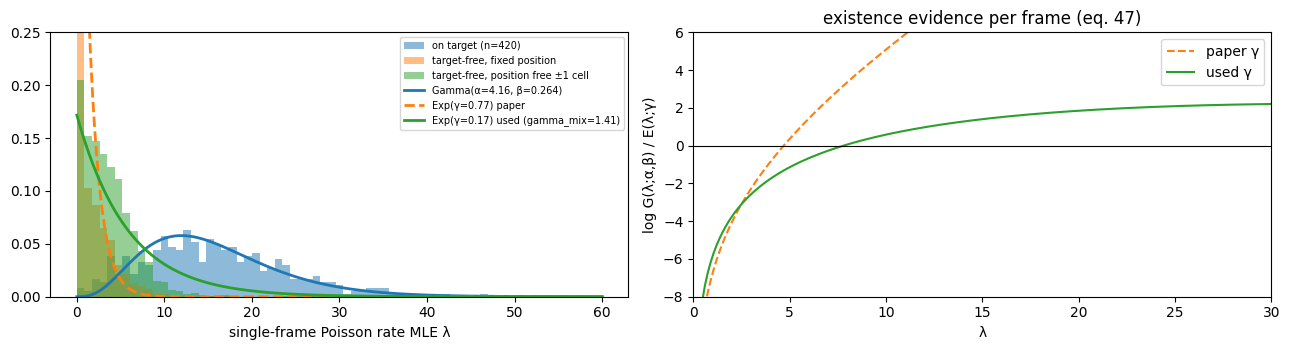

calibrated: {'alpha': 4.1596, 'beta': 0.2645, 'gamma': 0.7725, 'p_s': 0.9967, 'p_b': 0.0041, 'gamma_adapt': 0.2667} 
used:       {'alpha': 4.1596, 'beta': 0.2645, 'gamma': 0.172, 'p_s': 0.9904, 'p_b': 0.1227}


In [6]:
cfg_t, _ = TUNED["IE-PHPMHT"]
cal_t, diag = eb_calibrate(simulate(scn, SETUP["calib_seed"]), cfg_t, seed=SETUP["calib_seed"])
from scipy import stats
eff = effective_priors(cfg_t, cal_t)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
bins = np.linspace(0, max(60, np.percentile(diag["on"], 99)), 70)
ax[0].hist(diag["on"], bins, density=True, alpha=.5, label=f"on target (n={len(diag['on'])})")
ax[0].hist(diag["off"], bins, density=True, alpha=.5, label="target-free, fixed position")
ax[0].hist(diag["off_adapt"], bins, density=True, alpha=.5, label="target-free, position free ±1 cell")
x = np.linspace(0.01, bins[-1], 400)
ax[0].plot(x, stats.gamma.pdf(x, cal_t["alpha"], scale=1 / cal_t["beta"]), "C0", lw=2, label=f"Gamma(α={cal_t['alpha']:.2f}, β={cal_t['beta']:.3f})")
ax[0].plot(x, cal_t["gamma"] * np.exp(-cal_t["gamma"] * x), "C1--", lw=2, label=f"Exp(γ={cal_t['gamma']:.2f}) paper")
ax[0].plot(x, eff["gamma"] * np.exp(-eff["gamma"] * x), "C2", lw=2, label=f"Exp(γ={eff['gamma']:.2f}) used (gamma_mix={cfg_t.gamma_mix:.2f})")
ax[0].set_ylim(0, 0.25); ax[0].set_xlabel("single-frame Poisson rate MLE λ"); ax[0].legend(fontsize=7)
lr = lambda g: stats.gamma.logpdf(x, cal_t["alpha"], scale=1 / cal_t["beta"]) - (np.log(g) - g * x)
ax[1].plot(x, lr(cal_t["gamma"]), "C1--", label="paper γ"); ax[1].plot(x, lr(eff["gamma"]), "C2", label="used γ")
ax[1].axhline(0, c="k", lw=.8); ax[1].set_xlim(0, 30); ax[1].set_ylim(-8, 6)
ax[1].set_xlabel("λ"); ax[1].set_ylabel("log G(λ;α,β) / E(λ;γ)"); ax[1].legend(); ax[1].set_title("existence evidence per frame (eq. 47)")
plt.tight_layout(); plt.show()
print("calibrated:", {k: round(v, 4) for k, v in cal_t.items()}, "\nused:      ", {k: round(v, 4) for k, v in eff.items()})

## 4. Held-out comparison (test seeds 1–6)

Each algorithm runs with its **default** configuration and with its **calibrated** one. Latencies come from this
process, one algorithm at a time.

In [7]:
test = Bench(scn, SETUP["test_seeds"], pre=PRE)
cal_default_tbd = TBDCalibrator(scn, SETUP["calib_seed"])(DEF["IE-PHPMHT"][0])
det_runs = {}
for algo in ["GLMB-gibbs", "LMB-gibbs", "GNN"]:
    det_runs[f"{algo} (default)"] = DEF[algo]
    det_runs[f"{algo} (calibrated)"] = TUNED[algo]
tbd_runs = {"IE-PHPMHT (default)": (DEF["IE-PHPMHT"][0], cal_default_tbd),
            "IE-PHPMHT (calibrated)": TUNED["IE-PHPMHT"]}
t0 = time.perf_counter()
DF, RUNS = compare(test, det_runs, tbd_runs)
print(f"{time.perf_counter() - t0:.0f} s")

GLMB-gibbs (default)   GOSPA=  8.77  IDF1=0.61  MOTA=+0.51  track_recall=0.48  latency=  55.7 ms/frame


GLMB-gibbs (calibrated) GOSPA=  7.04  IDF1=0.73  MOTA=+0.63  track_recall=0.57  latency= 119.3 ms/frame


LMB-gibbs (default)    GOSPA=  9.10  IDF1=0.60  MOTA=+0.49  track_recall=0.40  latency=  56.5 ms/frame


LMB-gibbs (calibrated) GOSPA=  7.05  IDF1=0.73  MOTA=+0.64  track_recall=0.55  latency= 133.5 ms/frame


GNN (default)          GOSPA= 13.84  IDF1=0.43  MOTA=-0.20  track_recall=0.42  latency=  41.7 ms/frame


GNN (calibrated)       GOSPA= 10.49  IDF1=0.33  MOTA=+0.35  track_recall=0.18  latency=  42.5 ms/frame


IE-PHPMHT (default)    GOSPA= 58.93  IDF1=0.04  MOTA=-18.95  track_recall=0.33  latency=  11.8 ms/frame


IE-PHPMHT (calibrated) GOSPA= 10.27  IDF1=0.39  MOTA=+0.39  track_recall=0.32  latency=  10.4 ms/frame
302 s


In [8]:
mean, std = summary_table(DF)
order = [n for n in mean.index if "calibrated" in n] + [n for n in mean.index if "default" in n]
show = mean.loc[order].copy()
show.columns = [c.replace("_ms", " [ms]") for c in show.columns]
display(show.style.format("{:.3g}").background_gradient(subset=["GOSPA"], cmap="RdYlGn_r")
        .background_gradient(subset=["IDF1", "track_recall"], cmap="RdYlGn"))
print("± std over seeds (calibrated):")
display(std.loc[[n for n in order if "calibrated" in n], ["GOSPA", "IDF1", "MOTA", "track_recall", "lat_mean_ms"]])

,GOSPA,GOSPA_loc,GOSPA_missed,GOSPA_false,OSPA2,IDF1,MOTA,MOTP,track_recall,track_precision,MT,ML,ID_switches,lat_mean [ms],lat_p95 [ms],stage1 [ms],stage2 [ms]
algorithm,,,,,,,,,,,,,,,,,
GLMB-gibbs (calibrated),7.04,1.62,5.96,0.587,4.19,0.733,0.631,0.784,0.575,0.972,3.67,1,0.833,119,167,35.2,84
LMB-gibbs (calibrated),7.05,1.57,6.01,0.501,4.13,0.732,0.64,0.808,0.551,1,3.5,1.17,0.5,133,158,35.2,98.2
GNN (calibrated),10.5,1.56,9.85,0.301,6.93,0.327,0.35,0.847,0.18,0.812,1.17,2.67,5.67,42.5,48,37,5.5
IE-PHPMHT (calibrated),10.3,1.25,9.61,0.926,6.74,0.387,0.386,0.799,0.317,1,1.83,2.33,3.33,10.4,12.4,1.84,8.57
GLMB-gibbs (default),8.77,1.39,8.12,0.28,5.42,0.605,0.513,0.862,0.478,1,2.83,1.5,2.17,55.7,64.4,35.1,20.7
LMB-gibbs (default),9.1,1.27,8.5,0.354,5.59,0.599,0.491,0.834,0.398,0.833,2.5,2.17,1.33,56.5,67,35.1,21.4
GNN (default),13.8,1.92,7.84,9.77,7.26,0.432,-0.2,0.99,0.422,0.189,2.67,1.5,3.17,41.7,48.8,35.1,6.62
IE-PHPMHT (default),58.9,4.6,7.92,58,9.83,0.0394,-18.9,1.46,0.326,0.0153,1.83,2.5,8.5,11.8,13.5,1.85,9.9


± std over seeds (calibrated):


,GOSPA,IDF1,MOTA,track_recall,lat_mean_ms
algorithm,,,,,
GLMB-gibbs (calibrated),2.667,0.204,0.274,0.358,6.287
LMB-gibbs (calibrated),3.029,0.225,0.276,0.351,5.437
GNN (calibrated),3.212,0.207,0.274,0.190,3.283
IE-PHPMHT (calibrated),2.873,0.197,0.273,0.240,0.227


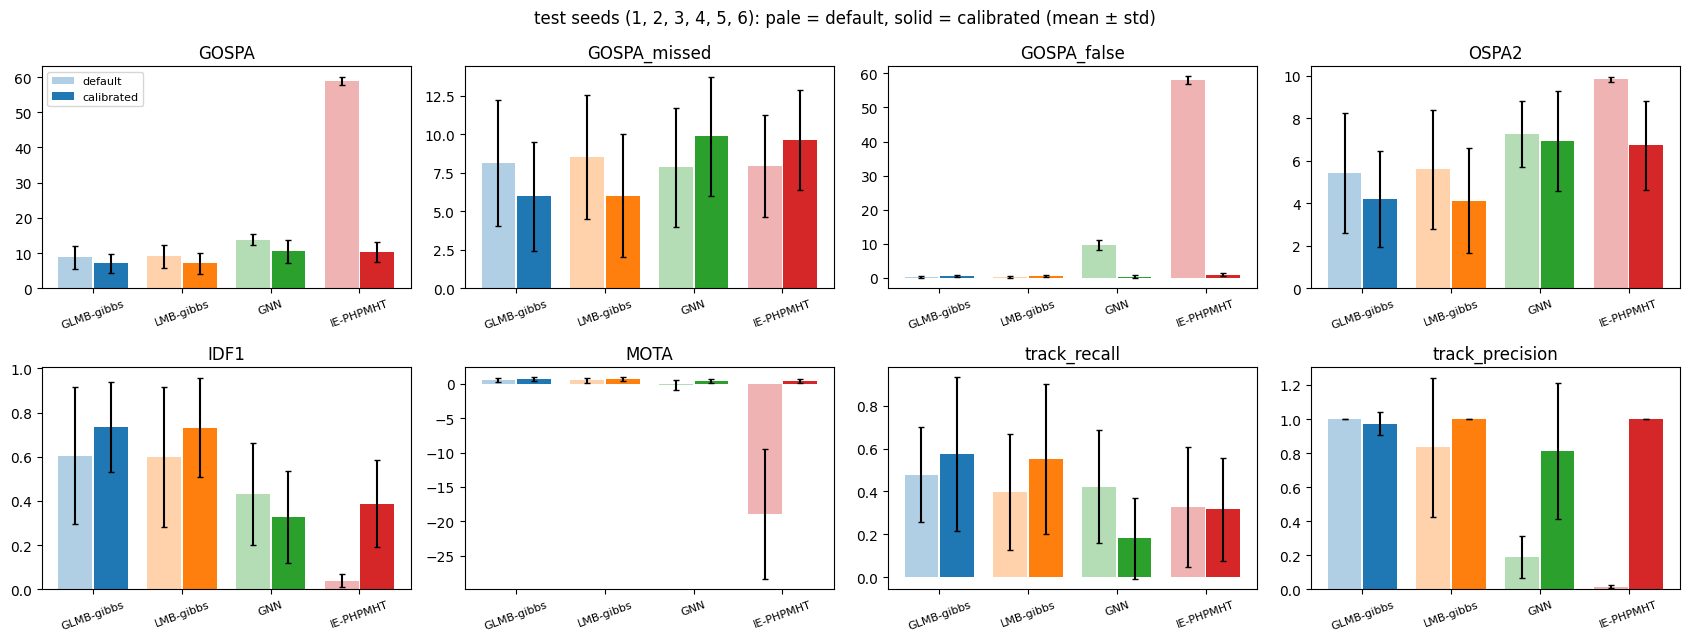

In [9]:
metrics = ["GOSPA", "GOSPA_missed", "GOSPA_false", "OSPA2", "IDF1", "MOTA", "track_recall", "track_precision"]
names = [n.replace(" (calibrated)", "") for n in order if "calibrated" in n]
fig, axs = plt.subplots(2, 4, figsize=(17, 6.5))
for ax, m in zip(axs.ravel(), metrics):
    for j, base in enumerate(names):
        for o, kind, alpha in ((-0.2, "default", 0.35), (0.2, "calibrated", 1.0)):
            d = DF[DF.algorithm == f"{base} ({kind})"][m]
            ax.bar(j + o, d.mean(), 0.38, yerr=d.std(), color=viz._algo_color(j), alpha=alpha, capsize=2,
                   label=kind if j == 0 else None)
    ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=20, fontsize=8); ax.set_title(m)
axs[0, 0].legend(fontsize=8)
fig.suptitle(f"test seeds {SETUP['test_seeds']}: pale = default, solid = calibrated (mean ± std)"); plt.tight_layout(); plt.show()

### Latency

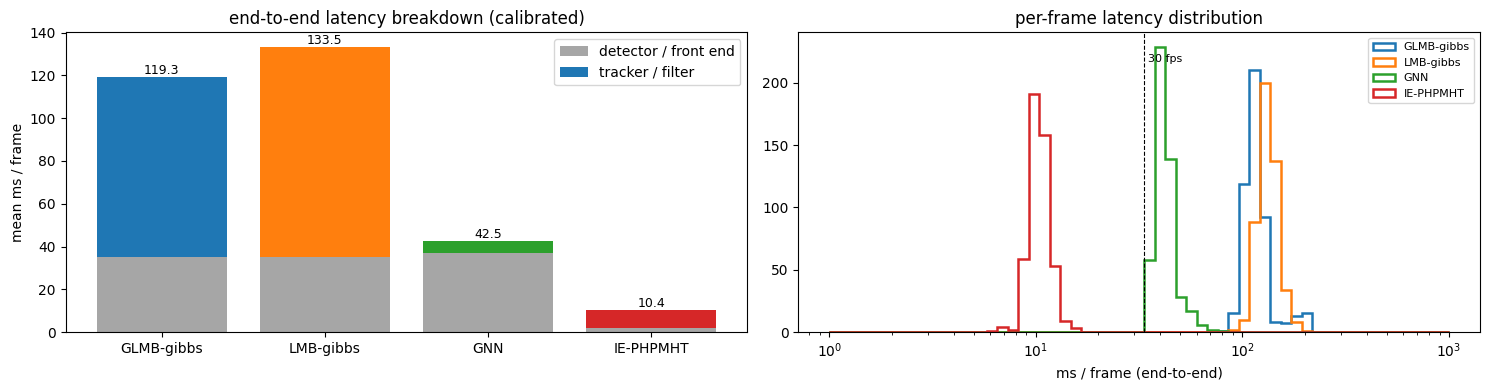

,stage1_ms,stage2_ms,lat_mean_ms,lat_p50_ms,lat_p95_ms,lat_p99_ms,lat_max_ms
algorithm,,,,,,,
GLMB-gibbs (calibrated),35.247,84.040,119.287,114.909,166.591,200.140,204.483
LMB-gibbs (calibrated),35.247,98.217,133.465,132.672,158.292,166.440,172.094
GNN (calibrated),37.017,5.496,42.513,41.732,48.040,55.932,61.797
IE-PHPMHT (calibrated),1.845,8.569,10.414,10.257,12.426,13.552,14.400


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
cal_names = [n for n in order if "calibrated" in n]
for j, n in enumerate(cal_names):
    s1 = np.concatenate([RUNS[n][s]["det_ms"] for s in test.seeds]); s2 = np.concatenate([RUNS[n][s]["trk_ms"] for s in test.seeds])
    ax[0].bar(j, s1.mean(), color="0.65", label="detector / front end" if j == 0 else None)
    ax[0].bar(j, s2.mean(), bottom=s1.mean(), color=viz._algo_color(j), label="tracker / filter" if j == 0 else None)
    ax[0].text(j, s1.mean() + s2.mean(), f"{s1.mean() + s2.mean():.1f}", ha="center", va="bottom", fontsize=9)
    ax[1].hist(s1 + s2, bins=np.logspace(0, 3, 60), histtype="step", lw=1.8, color=viz._algo_color(j), label=n.replace(" (calibrated)", ""))
ax[0].set_xticks(range(len(cal_names))); ax[0].set_xticklabels([n.replace(" (calibrated)", "") for n in cal_names])
ax[0].set_ylabel("mean ms / frame"); ax[0].legend(); ax[0].set_title("end-to-end latency breakdown (calibrated)")
ax[1].set_xscale("log"); ax[1].axvline(33.3, ls="--", c="k", lw=.8); ax[1].text(35, ax[1].get_ylim()[1] * .9, "30 fps", fontsize=8)
ax[1].set_xlabel("ms / frame (end-to-end)"); ax[1].legend(fontsize=8); ax[1].set_title("per-frame latency distribution")
plt.tight_layout(); plt.show()
display(DF.groupby("algorithm")[["stage1_ms", "stage2_ms", "lat_mean_ms", "lat_p50_ms", "lat_p95_ms", "lat_p99_ms", "lat_max_ms"]].mean().loc[cal_names])

### Visual check on one test seed

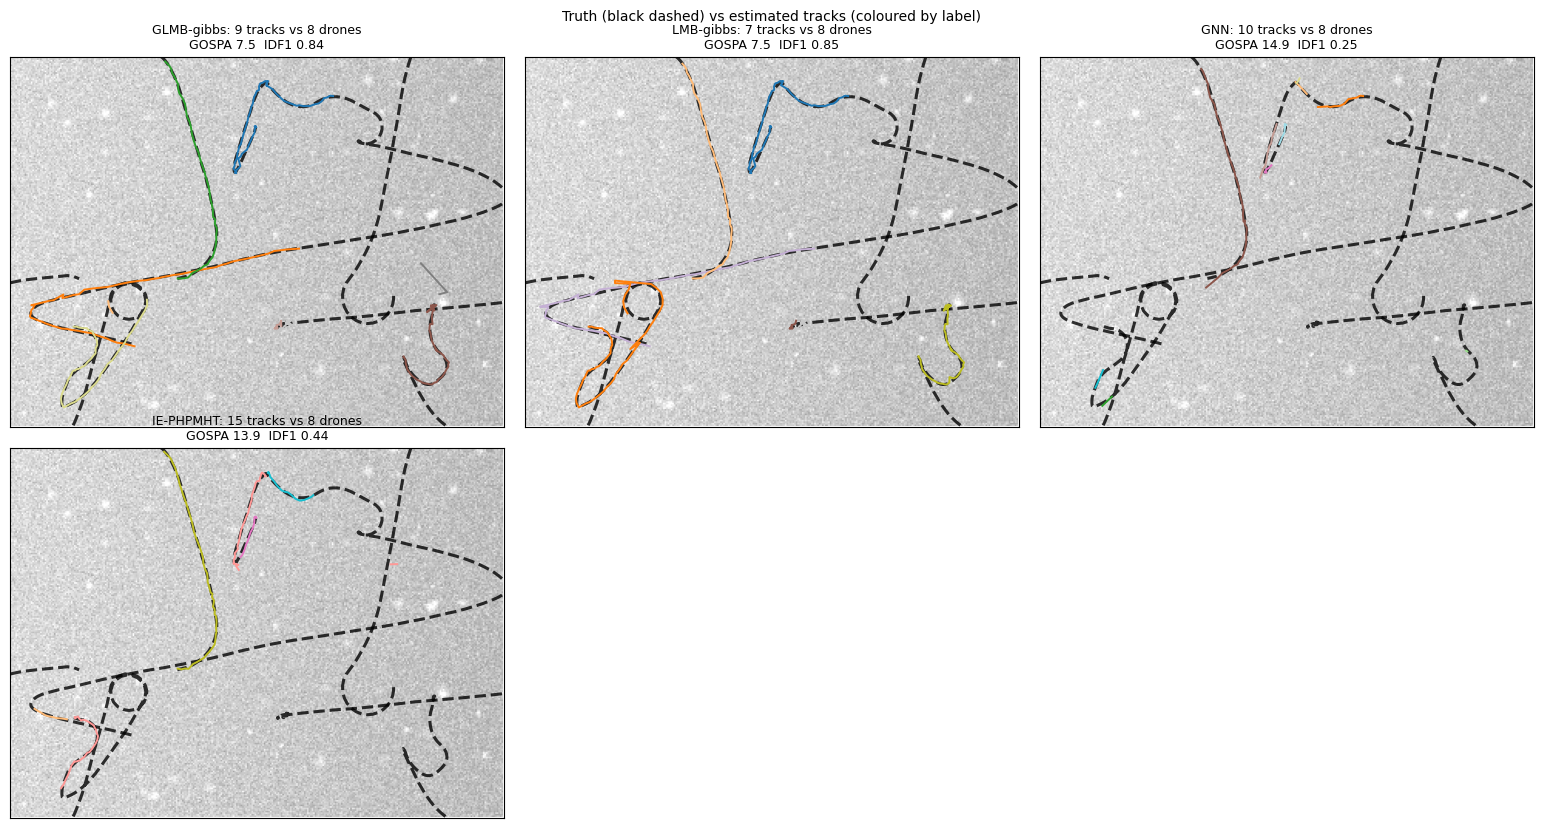

In [11]:
SEED = test.seeds[0]
ex = to_experiment(test, SEED, {n.replace(" (calibrated)", ""): RUNS[n] for n in cal_names}, TUNED["GLMB-gibbs"][0])
viz.plot_trajectories(ex); plt.show()

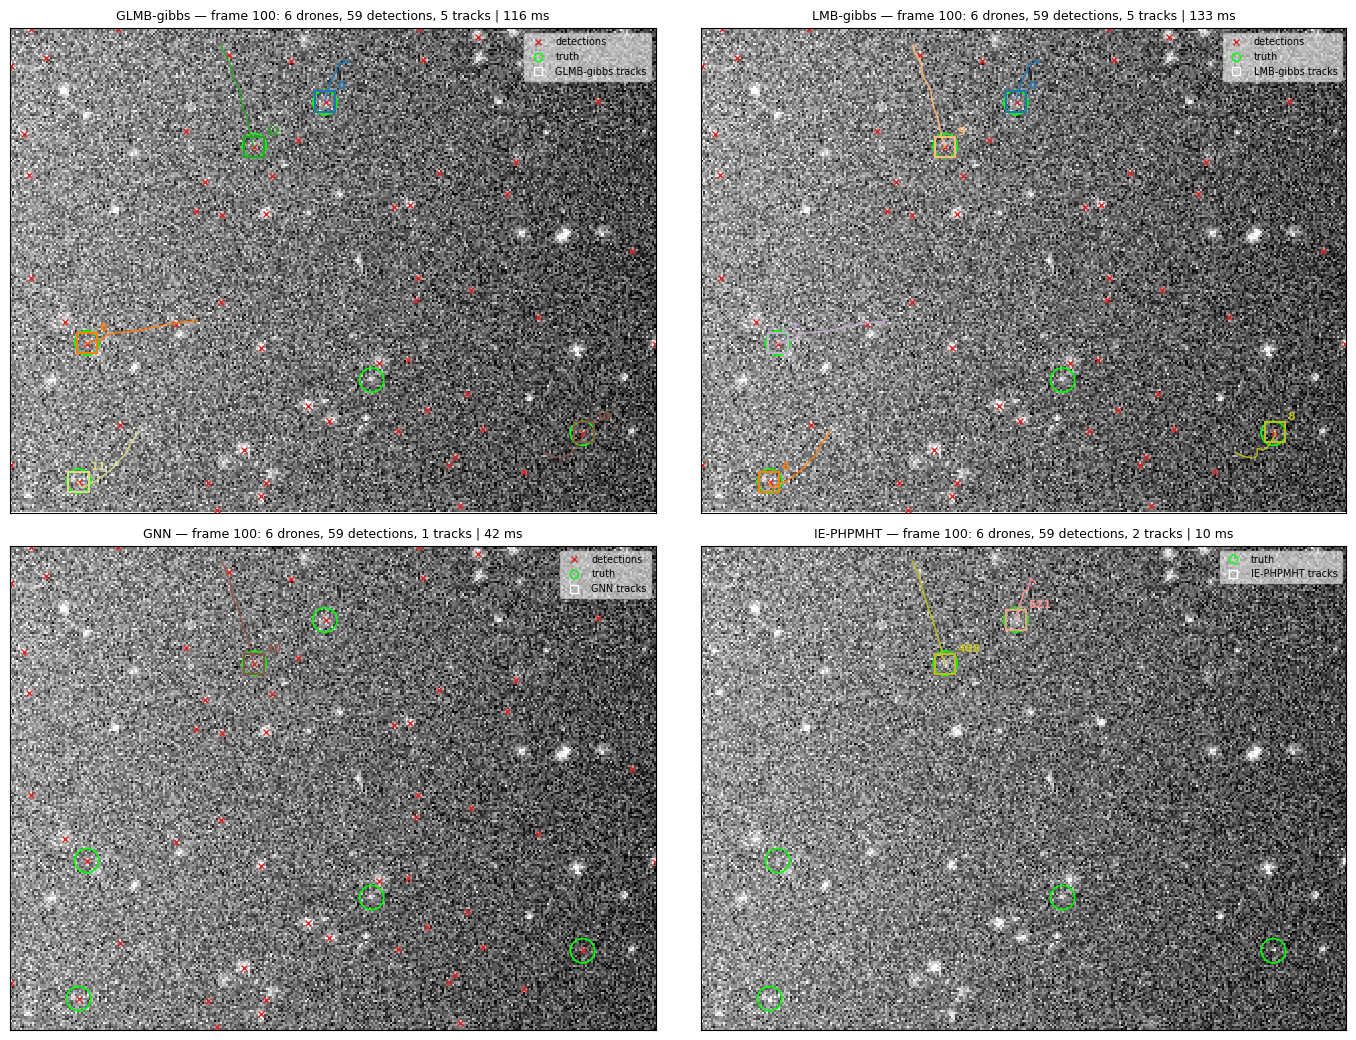

In [12]:
fig, axs = plt.subplots(2, 2, figsize=(14, 10.5))
for ax, name in zip(axs.ravel(), ex.runs):
    viz.draw_frame(ax, ex, PRE + 40, algo=name, show_dets=(name != "IE-PHPMHT"))
    ax.set_title(name + " — " + ax.get_title(), fontsize=9)
plt.tight_layout(); plt.show()

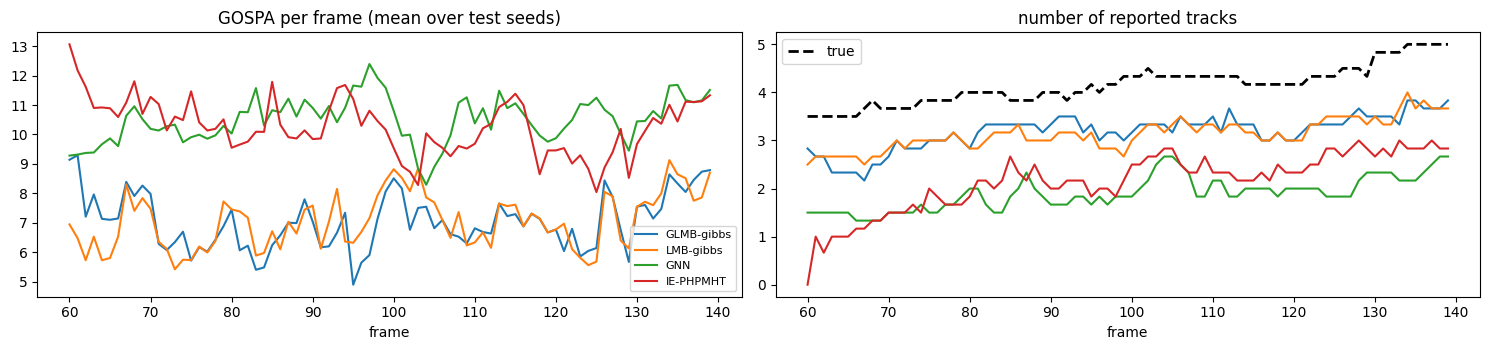

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
for j, n in enumerate(cal_names):
    g = np.mean([RUNS[n][s]["frame"]["gospa"] for s in test.seeds], 0)
    ce = np.mean([RUNS[n][s]["frame"]["card_est"] for s in test.seeds], 0)
    ax[0].plot(np.arange(PRE, PRE + len(g)), g, color=viz._algo_color(j), label=n.replace(" (calibrated)", ""))
    ax[1].plot(np.arange(PRE, PRE + len(ce)), ce, color=viz._algo_color(j))
ct = np.mean([RUNS[cal_names[0]][s]["frame"]["card_true"] for s in test.seeds], 0)
ax[1].plot(np.arange(PRE, PRE + len(ct)), ct, "k--", lw=2, label="true")
ax[0].set_title("GOSPA per frame (mean over test seeds)"); ax[1].set_title("number of reported tracks"); ax[0].legend(fontsize=8); ax[1].legend()
for a in ax: a.set_xlabel("frame")
plt.tight_layout(); plt.show()

## 5. Robustness: calibrated configurations across SNR

All configurations keep the parameters calibrated at the SETUP SNR, without retuning. IE-PHPMHT keeps its
priors from the calibration SNR. 2 seeds per point; set `RUN_SNR_SWEEP = False` to skip (≈ 5 min).

SNR 1.5 done


SNR 2.0 done


SNR 3.0 done


SNR 4.0 done


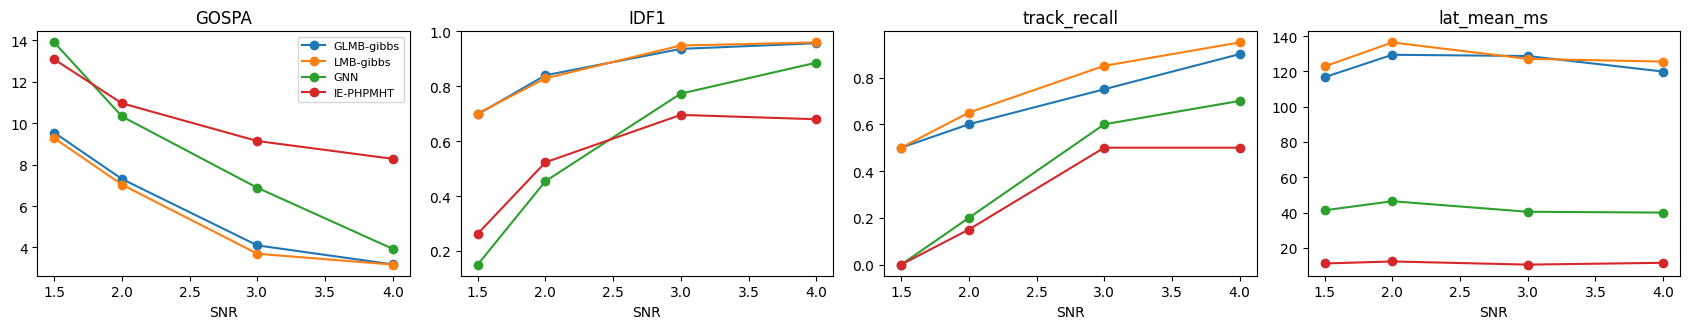

GOSPA                                   IDF1                            track_recall                          lat_mean_ms                            
algorithm GLMB-gibbs     GNN IE-PHPMHT LMB-gibbs GLMB-gibbs    GNN IE-PHPMHT LMB-gibbs   GLMB-gibbs  GNN IE-PHPMHT LMB-gibbs  GLMB-gibbs     GNN IE-PHPMHT LMB-gibbs
snr                                                                                                                                                                 
1.5            9.540  13.893    13.074     9.271      0.698  0.150     0.263     0.701         0.50  0.0      0.00      0.50     116.719  41.270    11.131   122.828
2.0            7.302  10.322    10.955     7.032      0.840  0.454     0.523     0.829         0.60  0.2      0.15      0.65     129.432  46.418    12.276   136.419
3.0            4.100   6.879     9.136     3.697      0.936  0.773     0.696     0.949         0.75  0.6      0.50      0.85     128.733  40.441    10.485   127.110
4.0            3.184   3.933     8.277     3.172      0.957  0.886     0.680     0.960         0.90  0.7      0.50      0.95     119.920  39.976    11.509   125.567

In [14]:
RUN_SNR_SWEEP = True
SNRS = [1.5, 2.0, 3.0, 4.0]
if RUN_SNR_SWEEP:
    rows = []
    for snr in SNRS:
        b = Bench(replace(scn, snr=snr), (21, 22), pre=PRE)
        df, _ = compare(b, {a: TUNED[a] for a in ["GLMB-gibbs", "LMB-gibbs", "GNN"]},
                        {"IE-PHPMHT": TUNED["IE-PHPMHT"]}, verbose=False)
        df["snr"] = snr; rows.append(df); print("SNR", snr, "done")
    SW = pd.concat(rows)
    fig, axs = plt.subplots(1, 4, figsize=(17, 3.4))
    for ax, m in zip(axs, ["GOSPA", "IDF1", "track_recall", "lat_mean_ms"]):
        for j, a in enumerate(["GLMB-gibbs", "LMB-gibbs", "GNN", "IE-PHPMHT"]):
            d = SW[SW.algorithm == a].groupby("snr")[m].mean()
            ax.plot(d.index, d.values, "o-", color=viz._algo_color(j), label=a)
        ax.set_xlabel("SNR"); ax.set_title(m)
    axs[0].legend(fontsize=8); plt.tight_layout(); plt.show()
    display(SW.groupby(["snr", "algorithm"])[["GOSPA", "IDF1", "track_recall", "lat_mean_ms"]].mean().unstack())

## 6. Conclusions (from the run above: SNR 2, clutter 1–5 px, test seeds 1–6)

| calibrated | GOSPA ↓ | IDF1 | MOTA | track recall | false part | latency (mean / p95) |
|---|---|---|---|---|---|---|
| **GLMB-gibbs** | **7.0** | **0.73** | 0.63 | **0.57** | 0.5 | 119 / 167 ms |
| **LMB-gibbs** | **7.1** | **0.73** | 0.64 | 0.55 | 0.5 | 133 / 158 ms |
| GNN | 10.5 | 0.33 | 0.35 | 0.18 | 0.3 | 43 / 48 ms |
| IE-PHPMHT | 10.3 | 0.39 | 0.39 | 0.32 | 0.9 | **10 / 12 ms** |

**Calibration matters for every algorithm, most of all for IE-PHPMHT.**
- With the project defaults and the paper's γ (rate of a Bernoulli at a fixed target-free position), IE-PHPMHT keeps about 60 self-sustaining false tracks: GOSPA 59.
- Calibrated, GOSPA drops to 10.3. The decisive settings: a γ based on the position-free off-target rate (`gamma_mix` ≈ 1.4), p_b ≈ 30× its empirical-Bayes value, and t_conf ≈ 0.7.
- GLMB and LMB gain about 20% (8.8 → 7.0), mostly by lowering the detector threshold from 4σ to about 3σ and letting the RFS filter reject the extra clutter.
- GNN cannot do that. Its best setting suppresses false tracks, which costs recall.

**Accuracy: GLMB and LMB are clearly best at SNR 2. IE-PHPMHT is level with GNN on GOSPA and better on identity.**
- IE-PHPMHT's error is almost entirely *missed* targets; its track precision is 1.0.
- It follows a drone accurately once it has a Bernoulli on it. But eq. 47 decides existence from a **single-frame** rate. At SNR 2 that rate (≈ 5–15) often falls below the broad on-target Gamma (mean ≈ 16), so evidence builds slowly and dim or fast drones are confirmed late or never.
- The SNR sweep confirms this. At SNR 3–4 the detect-then-track pipelines reach GOSPA 3–4, while IE-PHPMHT stays at 8–9 with track recall ≈ 0.5. It was calibrated at SNR 2 and not retuned, and the plateau suggests a structural limit (existence, birth or motion handling), not noise.

**Latency: IE-PHPMHT is 4–13× faster end to end, with the tightest tail.** It averages 10.4 ms per frame (p99 13.6 ms): 1.8 ms front end and 8.6 ms filter, in NumPy on one CPU thread.
- The detection pipelines pay about 35 ms for the detector alone (multi-scale LoG size gate).
- GLMB and LMB add 84–98 ms of tracking, because the calibrated low threshold triples the number of detections.
- Only IE-PHPMHT would run at 30 fps here without further optimisation.

**Caveats**
- 6 test seeds of 80 frames each; per-seed std of GOSPA is about 3, so GLMB and LMB are tied, and so are GNN and IE-PHPMHT.
- The IE-PHPMHT changes stay within calibration: γ definition, p_s, p_b and t_conf. The paper's algorithm is unchanged.
- Changes likely to close the recall gap, all outside this paper, not tried here:
  - multi-frame evidence for existence;
  - a less diffuse on-target prior (fit per size or SNR class);
  - a velocity-aware birth proposal for fast drones.
- Murty variants were left out of the calibration to save time. Earlier runs showed them close to Gibbs in accuracy and 2–3× slower.
- The trajectory plots draw the full truth including the 60-frame pre-roll; tracks are scored after it.
